# COMP4522 Project - Descriptive and Predictive Analytics

This notebook works **only** on the transformed dataset produced by `etl/etl_pipeline.py`
(`output/mining_dataset.csv` plus the aggregated summaries). The raw tables are not touched here,
and all joins and aggregation are done in pandas.

**Contents**
1. Load the transformed dataset
2. Descriptive analytics (distributions, effort vs revenue, store / category / time summaries)
3. Predictive analytics - linear regression `Revenue ~ Effort_Hours`
4. Prediction for a sale with 10 hours of effort
   - 4.1 Second model: regression on the Effort_Hours aggregated dataset
5. Model checks and limitations

In [45]:
%matplotlib inline
# Libraries used in this notebook
from pathlib import Path          # builds file paths that work on any operating system
import numpy as np                # numeric helpers (arrays, evenly spaced numbers)
import pandas as pd               # tables (DataFrames): loading, grouping, summaries
import matplotlib.pyplot as plt   # drawing charts
import seaborn as sns             # nicer statistical charts (used for the box plot)
from sklearn.linear_model import LinearRegression               # the regression model
from sklearn.model_selection import train_test_split            # splits data into train / test parts
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error  # accuracy measures

#  Chart style: one blue colour for data, red for highlights, light grey grid lines.
# One accent colour, light recessive grid, no top/right spines
BLUE, GREY, RED = "#2a6fba", "#9aa3ad", "#c0392b"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e8eb", "grid.linewidth": 0.8,
    "axes.edgecolor": "#7b838c", "axes.titleweight": "bold", "axes.titlesize": 12,
    "axes.labelcolor": "#33393f", "xtick.color": "#4a5159", "ytick.color": "#4a5159",
    "axes.axisbelow": True,
})

#  Load the transformed data created by etl/etl_pipeline.py 
# Jupyter runs from the notebook/ folder, so the data is in ../output.
# The fallback "output" covers the case where the notebook is run from the project root.
OUT = Path("../output") if Path("../output").exists() else Path("output")
# Main dataset: one row per valid sale. parse_dates turns Sale_Date into real dates.
sales = pd.read_csv(OUT / "mining_dataset.csv", parse_dates=["Sale_Date"])
# Aggregated tables built in the ETL: one row per employee / per store / per product category.
emp_sum = pd.read_csv(OUT / "employee_summary.csv")
store_sum = pd.read_csv(OUT / "store_summary.csv")
cat_sum = pd.read_csv(OUT / "category_summary.csv")
# Sanity check: shows (rows, columns) of the main dataset and how many employees and stores were loaded.
print("mining dataset:", sales.shape, "| employees:", len(emp_sum), "| stores:", len(store_sum))

mining dataset: (19604, 16) | employees: 98 | stores: 10


## 1. The transformed dataset

`mining_dataset.csv` has one row per *valid* sale, enriched by joining Sales -> Employee -> Store and Sales -> Product
in pandas, with computed attributes `Revenue_per_Hour`, `Revenue_per_Unit`, `Price_Realisation`
(revenue / (units x base price)), `Sale_Month` and `Sale_Weekday`. The aggregated tables
(`employee_summary`, `store_summary`, `category_summary`) are built from it with `groupby`.

In [46]:
# First 5 rows of the dataset, then summary statistics (count, mean, std, min, quartiles, max) for each numeric column.
display(sales.head())
display(sales.describe().T.round(2))
# Count missing values per column; only columns with at least one are listed (an empty result means none).
print("Missing values per column:\n", sales.isna().sum()[lambda s: s > 0])

,Employee_ID,Product_ID,Sale_Date,Units_Sold,Revenue,Effort_Hours,Store_ID,Store_Name,City,Category,Base_Price,Revenue_per_Hour,Revenue_per_Unit,Price_Realisation,Sale_Month,Sale_Weekday
0,1000,230,2024-01-03,5,263.81,10.79,4,Store_4,Vancouver,Clothing,102.18,24.449490,52.762000,0.516363,2024-01,Wednesday
1,1000,213,2024-01-04,8,127.49,2.52,4,Store_4,Vancouver,Clothing,106.30,50.591270,15.936250,0.149918,2024-01,Thursday
2,1000,219,2024-01-04,6,137.21,4.62,4,Store_4,Vancouver,Clothing,69.93,29.699134,22.868333,0.327017,2024-01,Thursday
3,1000,218,2024-01-05,6,171.00,5.03,4,Store_4,Vancouver,Electronics,290.42,33.996024,28.500000,0.098134,2024-01,Friday
4,1000,232,2024-01-05,2,315.99,11.43,4,Store_4,Vancouver,Home,16.59,27.645669,157.995000,9.523508,2024-01,Friday


,count,mean,min,25%,50%,75%,max,std
Employee_ID,19604.0,1049.678943,1000.0,1025.0,1050.0,1075.0,1099.0,28.988356
Product_ID,19604.0,219.549378,200.0,210.0,220.0,229.0,239.0,11.508351
Sale_Date,19604,2024-03-31 01:59:30.618241,2024-01-01 00:00:00,2024-02-15 00:00:00,2024-03-31 00:00:00,2024-05-15 00:00:00,2024-06-29 00:00:00,NaN
Units_Sold,19604.0,5.007039,1.0,3.0,5.0,7.0,9.0,2.584224
Revenue,19604.0,228.571752,0.0,150.4775,223.535,299.8675,528.08,97.415121
Effort_Hours,19604.0,6.497154,0.95,3.76,6.5,9.25,12.0,3.176334
Store_ID,19604.0,5.750663,1.0,3.0,6.0,8.0,10.0,2.943769
Base_Price,19604.0,171.09821,16.59,102.18,153.16,263.82,296.75,90.190172
Revenue_per_Hour,19604.0,38.827173,0.0,30.687942,35.837057,42.393422,151.556604,13.393522
Revenue_per_Unit,19604.0,66.142085,0.0,29.9255,45.6525,74.93875,427.6,61.803935


Missing values per column:
 Series([], dtype: int64)


The printout above confirms there are no missing values in the transformed dataset (the minimum effort is 0.95 hours, so
`Revenue_per_Hour` is always defined).

## 2. Descriptive analytics

### 2.1 Distribution of revenue and effort

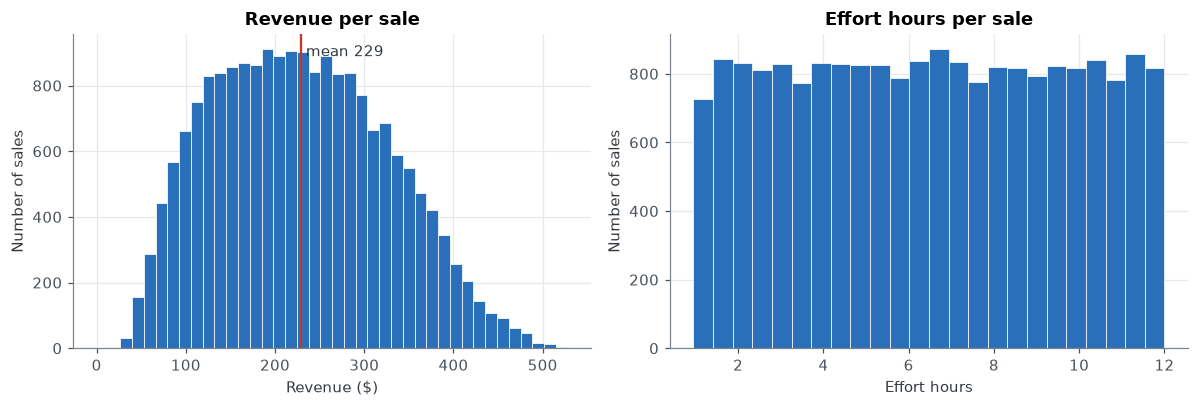

        Revenue  Effort_Hours  Units_Sold
mean     228.57          6.50        5.01
median   223.54          6.50        5.00
std       97.42          3.18        2.58
min        0.00          0.95        1.00
max      528.08         12.00        9.00


In [47]:
# Two charts side by side.
# Left: histogram of revenue per sale (bars = how many sales fall in each revenue range); red line = mean.
# Right: histogram of effort hours per sale.
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].hist(sales.Revenue, bins=40, color=BLUE, edgecolor="white", linewidth=0.5)
ax[0].axvline(sales.Revenue.mean(), color=RED, lw=1.5)
ax[0].text(sales.Revenue.mean() + 6, ax[0].get_ylim()[1] * 0.93, f"mean {sales.Revenue.mean():,.0f}", color="#33393f")
ax[0].set(title="Revenue per sale", xlabel="Revenue ($)", ylabel="Number of sales")
ax[1].hist(sales.Effort_Hours, bins=24, color=BLUE, edgecolor="white", linewidth=0.5)
ax[1].set(title="Effort hours per sale", xlabel="Effort hours", ylabel="Number of sales")
plt.tight_layout(); plt.show()
# Mean, median, standard deviation, minimum and maximum of the three numeric measures.
print(sales[["Revenue", "Effort_Hours", "Units_Sold"]].agg(["mean", "median", "std", "min", "max"]).round(2))

Revenue is roughly bell-shaped with a mild right tail (mean about $229, maximum about $528). Effort is close to uniform between
1 and 12 hours, with a visible cap at 12 hours - an observation that matters for the regression later (10 hours is well inside
the observed range, so the prediction is an interpolation, not an extrapolation).

### 2.2 Effort vs revenue

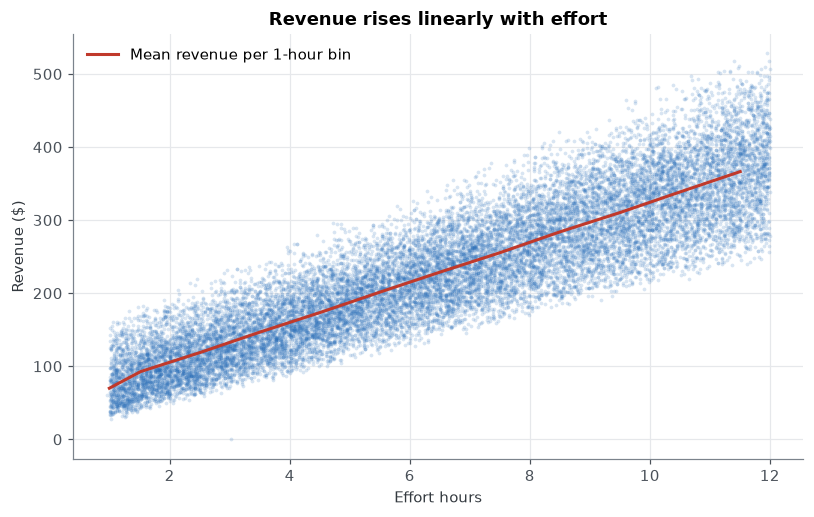

Pearson correlation (Effort, Revenue): 0.894
Pearson correlation (Units,  Revenue): 0.252
Pearson correlation (Effort, Units)  : -0.013


In [48]:
# Scatter plot of effort (x) against revenue (y): each dot is one sale. Dots are semi-transparent so crowded areas look darker.
fig, ax = plt.subplots(figsize=(7.5, 4.8))
ax.scatter(sales.Effort_Hours, sales.Revenue, s=6, alpha=0.18, color=BLUE, linewidths=0)
# Put sales into 1-hour effort bins and compute the average revenue in each bin; the red line joins these averages to show the trend.
b = sales.groupby(pd.cut(sales.Effort_Hours, np.arange(0, 12.5, 1)), observed=True).agg(x=("Effort_Hours", "mean"), y=("Revenue", "mean"))
ax.plot(b.x, b.y, color=RED, lw=2, label="Mean revenue per 1-hour bin")
ax.set(title="Revenue rises linearly with effort", xlabel="Effort hours", ylabel="Revenue ($)")
ax.legend(frameon=False, loc="upper left"); plt.tight_layout(); plt.show()
# Pearson correlation: +1 = perfect straight-line increase, 0 = no linear relationship.
# Effort vs revenue is the important one; units sold is shown for comparison.
print("Pearson correlation (Effort, Revenue): %.3f" % sales.Effort_Hours.corr(sales.Revenue))
print("Pearson correlation (Units,  Revenue): %.3f" % sales.Units_Sold.corr(sales.Revenue))
print("Pearson correlation (Effort, Units)  : %.3f" % sales.Effort_Hours.corr(sales.Units_Sold))

The relationship is strongly linear (r is about 0.89) and the binned means sit almost exactly on a straight line, so a linear model is appropriate.
The vertical spread grows with effort (fan shape), which is checked in section 5. Units sold is only weakly related to revenue and unrelated to effort.

### 2.3 Store-level, category-level and monthly summaries

,Store_ID,Store_Name,City,n_employees,n_sales,total_revenue,avg_revenue_per_sale,avg_effort_per_sale,revenue_per_effort_hour
0,10,Store_10,Calgary,15,2891,653085.16,225.90,6.45,35.01
1,4,Store_4,Vancouver,14,2776,639087.43,230.22,6.57,35.05
2,2,Store_2,Vancouver,13,2625,601410.28,229.11,6.53,35.11
3,7,Store_7,Vancouver,11,2257,519567.73,230.20,6.49,35.44
4,9,Store_9,Edmonton,10,1977,456025.06,230.67,6.56,35.15
5,3,Store_3,Vancouver,10,2010,451535.40,224.64,6.38,35.19
6,8,Store_8,Calgary,9,1776,404529.72,227.78,6.42,35.50
7,6,Store_6,Vancouver,6,1258,288563.43,229.38,6.53,35.12
8,1,Store_1,Edmonton,5,1019,234717.24,230.34,6.58,35.00
9,5,Store_5,Edmonton,5,1015,232399.17,228.96,6.47,35.37


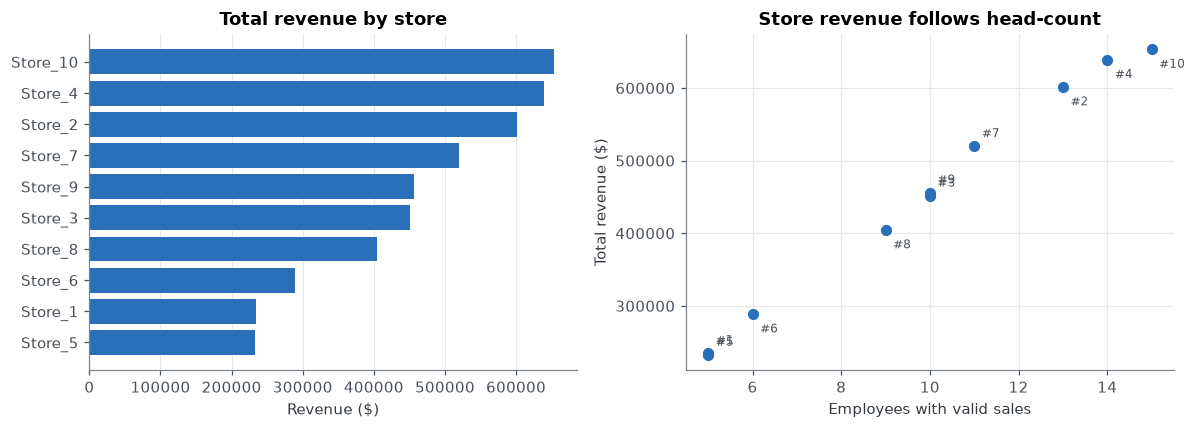

In [49]:
# Rank stores from highest to lowest total revenue and show their key figures as a table.
s = store_sum.sort_values("total_revenue", ascending=False)
display(s[["Store_ID", "Store_Name", "City", "n_employees", "n_sales", "total_revenue",
           "avg_revenue_per_sale", "avg_effort_per_sale", "revenue_per_effort_hour"]].round(2).reset_index(drop=True))

# Left: bar chart of total revenue per store.
# Right: each dot is a store, plotting number of employees against total revenue (stores with more staff earn more).
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].barh(s.Store_Name[::-1], s.total_revenue[::-1], color=BLUE)
ax[0].set(title="Total revenue by store", xlabel="Revenue ($)")
ax[0].grid(axis="y", visible=False)
ax[1].scatter(store_sum.n_employees, store_sum.total_revenue, color=BLUE, s=40)
for i, (_, r) in enumerate(store_sum.iterrows()):
    dy = 6 if i % 2 == 0 else -12  # alternate above/below so close points do not collide
    ax[1].annotate(r.Store_Name.replace("Store_", "#"), (r.n_employees, r.total_revenue), xytext=(5, dy), textcoords="offset points", fontsize=8, color="#4a5159")
ax[1].set(title="Store revenue follows head-count", xlabel="Employees with valid sales", ylabel="Total revenue ($)")
plt.tight_layout(); plt.show()

Store totals differ mostly because stores have different numbers of employees (right panel); per-sale revenue and revenue per effort hour
are nearly the same across stores (table), so no store is systematically more productive per hour of effort.

,Category,n_sales,total_units,total_revenue,total_effort_hours,avg_revenue_per_sale,avg_effort_per_sale,revenue_per_effort_hour
0,Clothing,6736,33580,1534412.06,43571.13,227.79,6.47,35.22
1,Electronics,4969,24963,1141938.05,32523.58,229.81,6.55,35.11
2,Food,4498,22648,1031979.32,29359.99,229.43,6.53,35.15
3,Home,3401,16967,772591.19,21915.51,227.17,6.44,35.25


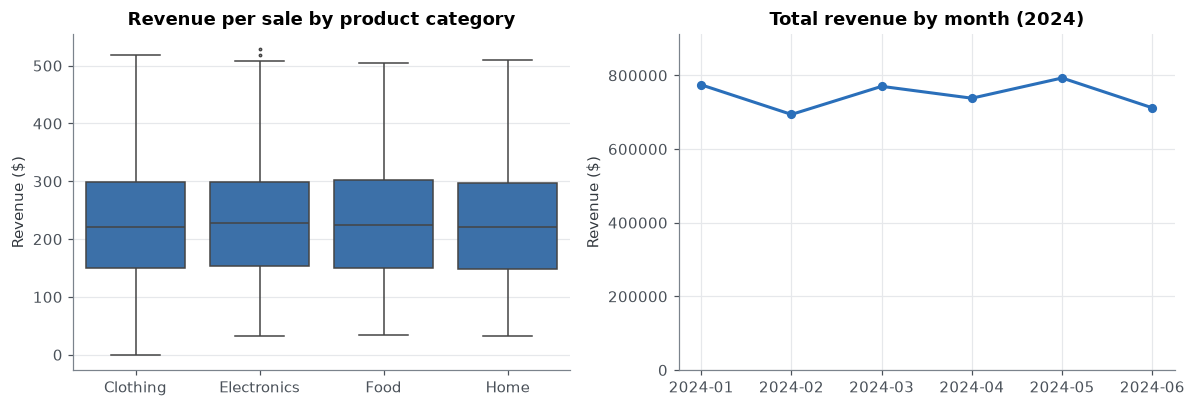

In [50]:
# Category summary table, then two charts.
# Left: box plot of revenue per sale for each category (box = middle 50% of sales, line inside = median, whiskers/dots = spread and outliers).
display(cat_sum.round(2))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
order = cat_sum.sort_values("total_revenue", ascending=False).Category
sns.boxplot(data=sales, x="Category", y="Revenue", order=order, color=BLUE, fliersize=1.5, linewidth=1, ax=ax[0])
ax[0].set(title="Revenue per sale by product category", xlabel="", ylabel="Revenue ($)")
# Right: total revenue for each month, drawn as a line.
m = sales.groupby("Sale_Month").Revenue.sum()
ax[1].plot(m.index, m.values, color=BLUE, lw=2, marker="o", ms=5)
ax[1].set(title="Total revenue by month (2024)", xlabel="", ylabel="Revenue ($)", ylim=(0, m.max() * 1.15))
plt.tight_layout(); plt.show()

Categories and cities look alike in revenue per sale, so product category and location are not strong drivers; effort is.
Monthly totals mostly reflect the number of days and sales in each month (February is shortest).

### 2.4 Employee-level view

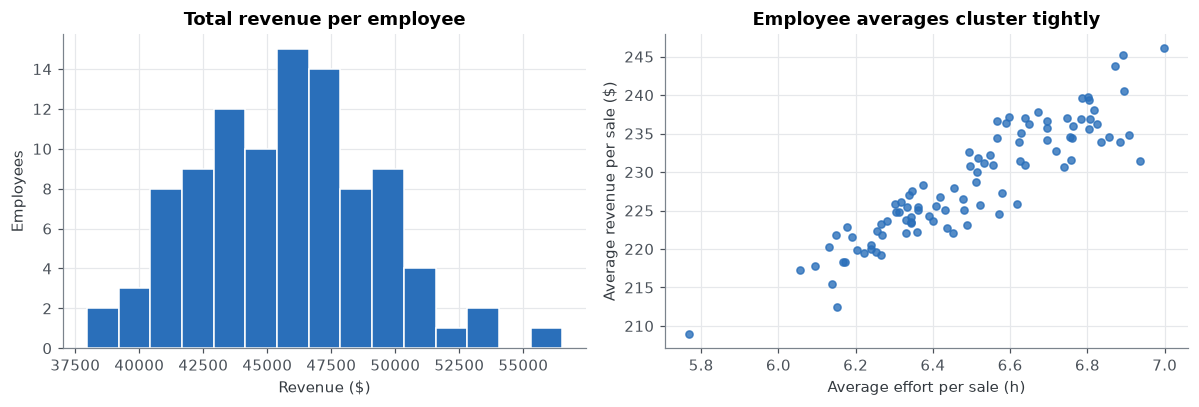

Range of employee-average effort per sale: 5.77 - 7.00 hours


In [51]:
# Left: how total revenue is spread across employees.
# Right: each dot is an employee, showing their average effort and average revenue per sale.
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].hist(emp_sum.total_revenue, bins=15, color=BLUE, edgecolor="white")
ax[0].set(title="Total revenue per employee", xlabel="Revenue ($)", ylabel="Employees")
ax[1].scatter(emp_sum.avg_effort_per_sale, emp_sum.avg_revenue_per_sale, color=BLUE, s=22, alpha=0.8)
ax[1].set(title="Employee averages cluster tightly", xlabel="Average effort per sale (h)", ylabel="Average revenue per sale ($)")
plt.tight_layout(); plt.show()
# Smallest and largest average effort per sale among employees. They are all close to 6.5 hours, which is why the model uses individual sales (see the text below).
print("Range of employee-average effort per sale: %.2f - %.2f hours" % (emp_sum.avg_effort_per_sale.min(), emp_sum.avg_effort_per_sale.max()))

Employee averages only span roughly 5.8 to 7.0 hours, so a model fitted on employee-level averages could not support a 10-hour prediction without heavy
extrapolation. This is the main reason the regression below is fitted on individual sale records.

## 3. Predictive analytics: linear regression

**Design decision.** The question is *the revenue of an employee's next sale at 10 hours of effort*, so the unit of analysis must be one sale.
Model: `Revenue = b0 + b1 x Effort_Hours`, fitted with scikit-learn `LinearRegression`.
First an 80/20 random split to estimate out-of-sample accuracy, then a final model on all 19,604 valid sales.

In [52]:
#  Prepare the data for scikit-learn ---
# X = the independent variable (input). The double brackets keep it as a table, which scikit-learn requires.
# y = the dependent variable (what we want to predict).
X = sales[["Effort_Hours"]]
y = sales["Revenue"]
# Hold-back test: randomly keep 80% of the sales for training and 20% for testing. random_state=42 makes the split repeatable.
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42)

# Fit a straight line on the training part only, then predict the revenue of the unseen test part.
check = LinearRegression().fit(X_tr, y_tr)
pred = check.predict(X_te)
# Accuracy on the unseen 20%: R2 = share of the variation in revenue explained by effort (1 = perfect);
# RMSE and MAE = typical size of the prediction error in dollars.
print("Hold-out (20%%) results  ->  R2 = %.3f | RMSE = $%.2f | MAE = $%.2f"
      % (r2_score(y_te, pred), mean_squared_error(y_te, pred) ** 0.5, mean_absolute_error(y_te, pred)))

# FINAL MODEL: fit the line again using all valid sales. This is the model used for the prediction below.
model = LinearRegression().fit(X, y)
print("\nFinal model on all valid sales")
# The fitted line is: Revenue = b0 + b1 x Effort_Hours.
# b0 (intercept) = predicted revenue at 0 hours; b1 (slope) = extra revenue gained for every extra effort hour.
print("  intercept b0 = %.3f" % model.intercept_)
print("  slope     b1 = %.3f  (extra revenue per additional effort hour)" % model.coef_[0])
print("  R2 (all data) = %.3f" % model.score(X, y))

Hold-out (20%) results  ->  R2 = 0.794 | RMSE = $44.12 | MAE = $35.49

Final model on all valid sales
  intercept b0 = 50.481
  slope     b1 = 27.411  (extra revenue per additional effort hour)
  R2 (all data) = 0.799


## 4. Prediction: next sale with 10 hours of effort

Predicted revenue for a sale with 10 hours of effort: $324.59
Approximate 95% prediction interval for a single sale   : $238.94 - $410.23


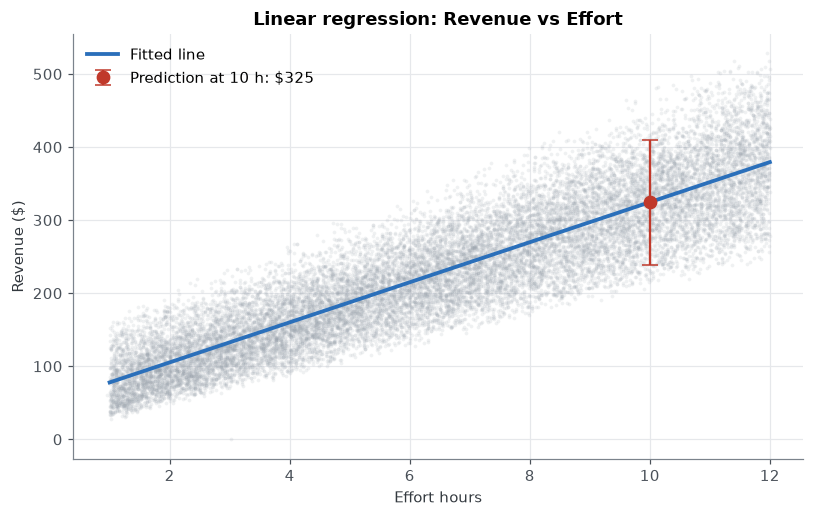

In [53]:
#  The assignment question: expected revenue of a sale made with 10 hours of effort 
hours = 10
# predict() needs a table with the same column name used in training; [0] takes the single predicted number.
point = float(model.predict(pd.DataFrame({"Effort_Hours": [hours]}))[0])
# Residual = actual revenue minus the model prediction. Their spread shows how far a single sale can be from the line.
resid = y - model.predict(X)
# Standard deviation of the residuals (ddof=2 because two values, b0 and b1, were estimated).
# Approximate 95% prediction interval for one sale = prediction +/- 1.96 x this standard deviation.
sd = resid.std(ddof=2)
lo, hi = point - 1.96 * sd, point + 1.96 * sd
# Print the answer.
print(f"Predicted revenue for a sale with {hours} hours of effort: ${point:,.2f}")
print(f"Approximate 95% prediction interval for a single sale   : ${lo:,.2f} - ${hi:,.2f}")

# Chart: all sales in grey, the fitted line in blue, and the 10-hour prediction with its interval in red.
fig, ax = plt.subplots(figsize=(7.5, 4.8))
ax.scatter(X.Effort_Hours, y, s=6, alpha=0.15, color=GREY, linewidths=0)
xs = np.linspace(1, 12, 50)
ax.plot(xs, model.predict(pd.DataFrame({"Effort_Hours": xs})), color=BLUE, lw=2.5, label="Fitted line")
ax.errorbar([hours], [point], yerr=[[point - lo], [hi - point]], fmt="o", color=RED, ms=8, capsize=5, label=f"Prediction at {hours} h: ${point:,.0f}")
ax.set(title="Linear regression: Revenue vs Effort", xlabel="Effort hours", ylabel="Revenue ($)")
ax.legend(frameon=False, loc="upper left"); plt.tight_layout(); plt.show()

**Result.** With 10 hours of effort, the model predicts an average revenue of about **$324.6** for the next sale; individual sales are expected to land
roughly between $239 and $410 (95% prediction interval).

### 4.1 Second model: regression on the Effort_Hours aggregated dataset
The ETL builds that table in pandas (`output/effort_aggregated.csv`): **one row per Effort_Hours value**, with the average
revenue `avg_rev` and the number of sales `n_sales` behind it. Here the same linear regression is fitted on that table, using exactly the same steps
(80/20 split, `random_state=42`, then a final model on all rows) so the two models can be compared.

In [54]:
# Aggregated dataset made by the ETL (pandas groupby on Effort_Hours): average revenue for each effort value.
agg = pd.read_csv(OUT / "effort_aggregated.csv")
print("aggregated dataset:", agg.shape)
print(agg.head())

# X = effort, y = average revenue at that effort.
Xa = agg[["Effort_Hours"]]
ya = agg["avg_rev"]

# Hold-back test: 80% of the rows to fit the line, 20% to check it on rows it has not seen.
Xa_tr, Xa_te, ya_tr, ya_te = train_test_split(Xa, ya, test_size=0.2, random_state=42)
check_a = LinearRegression().fit(Xa_tr, ya_tr)
pred_a = check_a.predict(Xa_te)
print("\nHold-out (20%%) results  ->  R2 = %.3f | RMSE = $%.2f | MAE = $%.2f"
      % (r2_score(ya_te, pred_a), mean_squared_error(ya_te, pred_a) ** 0.5, mean_absolute_error(ya_te, pred_a)))

# FINAL MODEL on all rows of the aggregated dataset, then the prediction for 10 hours of effort.
model_a = LinearRegression().fit(Xa, ya)
point_a = float(model_a.predict(pd.DataFrame({"Effort_Hours": [10]}))[0])
print("\nFinal model on the aggregated dataset")
print("  intercept b0 = %.3f" % model_a.intercept_)
print("  slope     b1 = %.3f  (extra average revenue per additional effort hour)" % model_a.coef_[0])
print(f"\nPredicted revenue at 10 hours of effort (aggregated model): ${point_a:,.2f}")

aggregated dataset: (1102, 3)
   Effort_Hours    avg_rev  n_sales
0          0.95  60.100000        1
1          1.00  71.055556        9
2          1.01  74.472667       15
3          1.02  69.135000       16
4          1.03  84.664118       17

Hold-out (20%) results  ->  R2 = 0.986 | RMSE = $10.05 | MAE = $7.93

Final model on the aggregated dataset
  intercept b0 = 50.463
  slope     b1 = 27.415  (extra average revenue per additional effort hour)

Predicted revenue at 10 hours of effort (aggregated model): $324.62


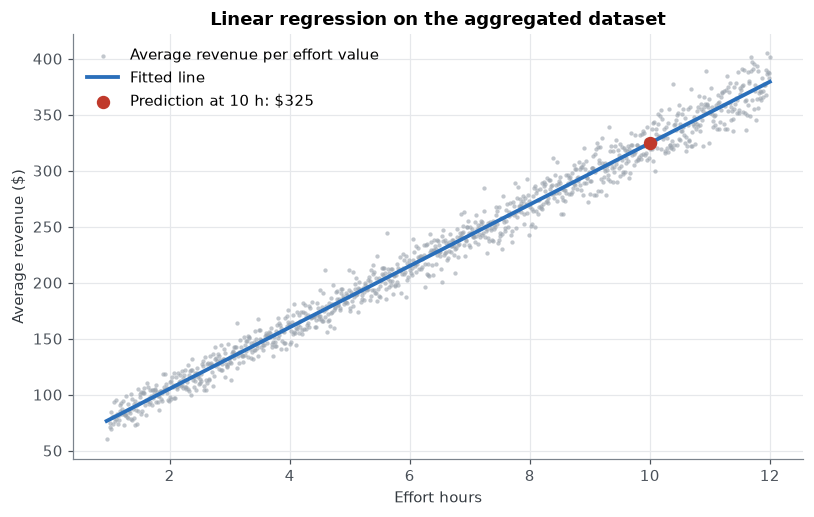

                        per-sale model  aggregated model
intercept b0                    50.481            50.463
slope b1                        27.411            27.415
R2 (all data)                    0.799             0.985
prediction at 10 h ($)         324.587           324.615


In [55]:
# Chart: every Effort_Hours value as a dot (its average revenue), the fitted line, and the 10-hour prediction.
fig, ax = plt.subplots(figsize=(7.5, 4.8))
ax.scatter(agg.Effort_Hours, agg.avg_rev, s=8, alpha=0.6, color=GREY, linewidths=0, label="Average revenue per effort value")
xs = np.linspace(agg.Effort_Hours.min(), agg.Effort_Hours.max(), 50)
ax.plot(xs, model_a.predict(pd.DataFrame({"Effort_Hours": xs})), color=BLUE, lw=2.5, label="Fitted line")
ax.scatter([10], [point_a], color=RED, s=60, zorder=5, label=f"Prediction at 10 h: ${point_a:,.0f}")
ax.set(title="Linear regression on the aggregated dataset", xlabel="Effort hours", ylabel="Average revenue ($)")
ax.legend(frameon=False, loc="upper left"); plt.tight_layout(); plt.show()

# Side-by-side comparison of the two models (per-sale model from section 3-4 versus the aggregated model above).
print(pd.DataFrame({
    "per-sale model": [model.intercept_, model.coef_[0], model.score(X, y), point],
    "aggregated model": [model_a.intercept_, model_a.coef_[0], model_a.score(Xa, ya), point_a],
}, index=["intercept b0", "slope b1", "R2 (all data)", "prediction at 10 h ($)"]).round(3))

## 5. Model checks and limitations

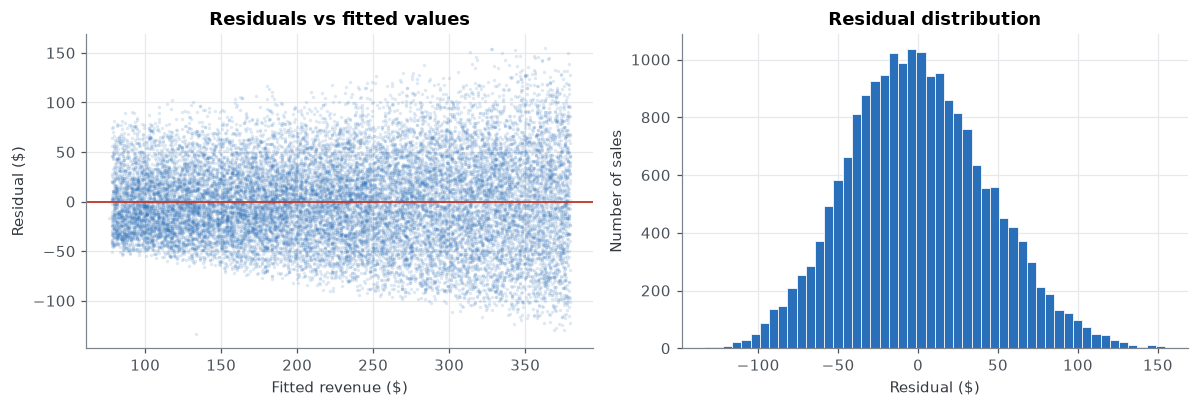

Residual std. dev. by effort band:
Effort_Hours
(0, 3]     31.7
(3, 6]     36.4
(6, 9]     44.7
(9, 12]    54.9


In [56]:
#  Model checks --
# fitted = the revenue the model predicts for every sale.
# Left chart: residuals against predicted values. A cloud centred on 0 means no bias; a widening "fan" means errors grow with effort.
# Right chart: histogram of residuals, which should look roughly bell-shaped and centred on 0.
fitted = model.predict(X)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].scatter(fitted, resid, s=5, alpha=0.15, color=BLUE, linewidths=0)
ax[0].axhline(0, color=RED, lw=1.2)
ax[0].set(title="Residuals vs fitted values", xlabel="Fitted revenue ($)", ylabel="Residual ($)")
ax[1].hist(resid, bins=50, color=BLUE, edgecolor="white", linewidth=0.5)
ax[1].set(title="Residual distribution", xlabel="Residual ($)", ylabel="Number of sales")
plt.tight_layout(); plt.show()

# Standard deviation of the residuals inside four effort bands: it grows with effort, so high-effort predictions are less certain.
bins = pd.cut(sales.Effort_Hours, [0, 3, 6, 9, 12])
print("Residual std. dev. by effort band:")
print(resid.groupby(bins, observed=True).std().round(1).to_string())

- **Fit quality:** R2 is about 0.79-0.80 on the hold-out set and on all data, so the model does not overfit; each extra hour of effort adds about $27.4 revenue.
- **Residuals** are centred on zero and roughly symmetric, but their spread increases with effort (heteroscedasticity). Point predictions are unbiased, but a single pooled
  interval is too narrow at high effort and too wide at low effort, so the interval above is only approximate (the 10-hour band has a residual spread of about $55 versus $44 pooled).
- **Scope:** 10 hours lies inside the observed 1-12 hour range, so the prediction is an interpolation. Effort explains about 80% of revenue variance; the rest
  (product, price, customer behaviour) is not modelled. Employee date fields were corrupted in the source and could not be used.
- **Data cleaning effect:** 396 of the 20,000 original sales rows (about 2%) were removed in the ETL (invalid foreign keys, negative revenue, negative effort);
  see the report and `output/discard_log.csv`.